# Code

## Load and Merge Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

# Works whether this is run from the repo root or from the 'Narrative Analysis' folder
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = ROOT / "data"
FIG_DIR = ROOT / "Narrative Analysis" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 418
N_BOOT = 10_000
rng = np.random.default_rng(SEED)

emis = pd.read_csv(DATA / "CommunityAreas_LocalEmission2019.csv", encoding="utf-8-sig")
inc_raw = pd.read_csv(DATA / "Chicago_Median_Income_By_Community_Area.csv")

# Income file has a description row under the header; keep only real community areas
inc = inc_raw[inc_raw["Layer"] == "Community area"].copy()
inc["GEOID"] = inc["GEOID"].astype(int)
inc["median_income"] = pd.to_numeric(inc["INC_2020-2024"])

# Join on community area number
df = emis.merge(inc[["GEOID", "Name", "median_income"]], left_on="CCA_NUM", right_on="GEOID", how="inner")
print("Emission rows:", len(emis), "| Income rows:", len(inc), "| Matched:", len(df))

Emission rows: 77 | Income rows: 77 | Matched: 77


## Build Variables

In [2]:
# AREA is in acres (the Sq_mi column is all zeros, so it is not used)
df["sq_mi"] = df["AREA"] / 640

# X = how much residents drive (vehicle miles per household per year, CMAP estimate)
df["res_vmt"] = df["RES_VMT"]

# Y = on-road CO2 emitted inside the area (all vehicles, incl. through traffic) per square mile
df["traffic_co2_per_sqmi"] = df["ONROAD_CO2"] / df["sq_mi"]

# Used in the checks
df["pop_density"] = df["POP"] / df["sq_mi"]
df["jobs_per_resident"] = df["JOBS"] / df["POP"]

df[["res_vmt", "traffic_co2_per_sqmi", "pop_density", "median_income"]].describe().round(1)

,res_vmt,traffic_co2_per_sqmi,pop_density,median_income
count,77.0,77.0,77.0,77.0
mean,11651.8,39436.1,13241.4,76728.5
std,3447.4,51309.7,7429.1,31574.0
min,5747.0,10939.7,1006.0,17398.6
25%,8466.0,20174.9,8160.7,55452.3
50%,11382.0,26899.2,11697.2,71435.7
75%,14196.0,42758.1,16552.2,93801.8
max,21010.0,410016.6,38466.0,161083.8


## Spearman Correlation: Resident Driving vs. Traffic CO2

In [3]:
def spearman_boot(x, y, n_boot=N_BOOT):
    x, y = np.asarray(x), np.asarray(y)
    rho = stats.spearmanr(x, y).statistic
    idx = rng.integers(0, len(x), size=(n_boot, len(x)))
    boots = np.array([stats.spearmanr(x[i], y[i]).statistic for i in idx])
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return rho, lo, hi

rho, lo, hi = spearman_boot(df["res_vmt"], df["traffic_co2_per_sqmi"])
print(f"Spearman rho = {rho:.3f}")
print(f"95% bootstrap CI = [{lo:.3f}, {hi:.3f}]")
print(f"n = {len(df)}")

Spearman rho = -0.315
95% bootstrap CI = [-0.532, -0.070]
n = 77


## Permutation Test (Chance)

In [4]:
# H0: no association between resident driving and traffic CO2 per sq mi (rho = 0)
# Ha: rho != 0
alpha = 0.05

x, y = df["res_vmt"].to_numpy(), df["traffic_co2_per_sqmi"].to_numpy()
obs = abs(stats.spearmanr(x, y).statistic)
null = np.array([abs(stats.spearmanr(x, rng.permutation(y)).statistic) for _ in range(N_BOOT)])
p_perm = (np.sum(null >= obs) + 1) / (N_BOOT + 1)

print("H0: rho = 0")
print("Ha: rho != 0")
print("Significance level:", alpha)
print(f"\nPermutation p-value ({N_BOOT:,} shuffles): {p_perm:.4f}")

if p_perm < alpha:
    print("\nReject H0.")
    print("A correlation this strong is unlikely to appear by chance.")
else:
    print("\nFail to reject H0.")
    print("The correlation could plausibly be due to chance.")

H0: rho = 0
Ha: rho != 0
Significance level: 0.05

Permutation p-value (10,000 shuffles): 0.0062

Reject H0.
A correlation this strong is unlikely to appear by chance.


## Figure

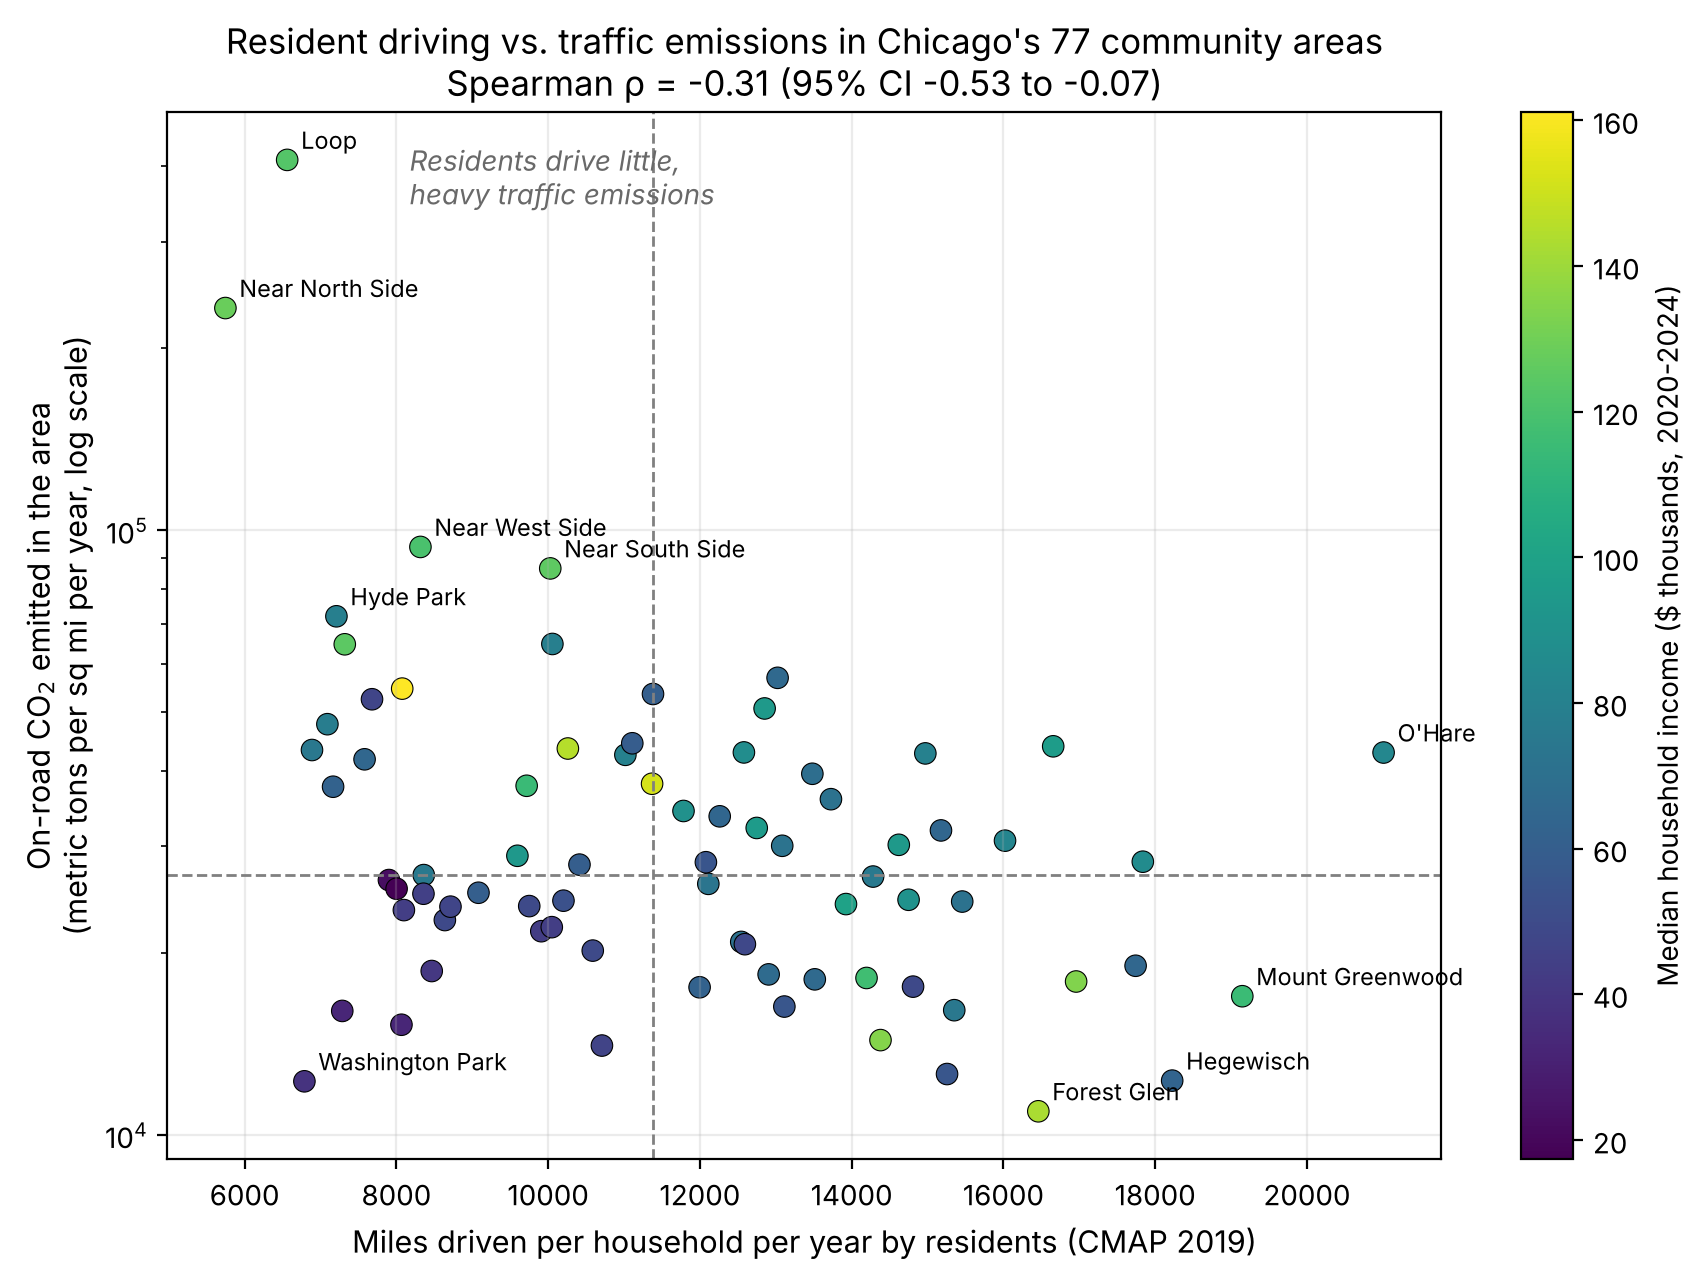

In [5]:
vmt_med = df["res_vmt"].median()
traf_med = df["traffic_co2_per_sqmi"].median()

fig, ax = plt.subplots(figsize=(9, 6.5))
sc = ax.scatter(df["res_vmt"], df["traffic_co2_per_sqmi"], c=df["median_income"] / 1000,
                cmap="viridis", s=60, edgecolor="black", linewidth=0.4)
ax.set_yscale("log")
ax.axvline(vmt_med, color="gray", ls="--", lw=1)
ax.axhline(traf_med, color="gray", ls="--", lw=1)
ax.text(0.19, 0.97, "Residents drive little,\nheavy traffic emissions", transform=ax.transAxes,
        va="top", fontsize=10, color="dimgray", style="italic")

label = set(df.nlargest(5, "traffic_co2_per_sqmi")["Name"]) | set(df.nsmallest(3, "traffic_co2_per_sqmi")["Name"]) \
        | set(df.nlargest(3, "res_vmt")["Name"]) | ({"O'Hare"} & set(df["Name"]))
for _, r in df[df["Name"].isin(label)].iterrows():
    ax.annotate(r["Name"], (r["res_vmt"], r["traffic_co2_per_sqmi"]), xytext=(5, 4),
                textcoords="offset points", fontsize=8.5)

cb = fig.colorbar(sc, ax=ax)
cb.set_label("Median household income ($ thousands, 2020-2024)", fontsize=10)
ax.set_xlabel("Miles driven per household per year by residents (CMAP 2019)", fontsize=11)
ax.set_ylabel("On-road CO$_2$ emitted in the area\n(metric tons per sq mi per year, log scale)", fontsize=11)
ax.set_title(f"Resident driving vs. traffic emissions in Chicago's {len(df)} community areas\n"
             f"Spearman \u03c1 = {rho:.2f} (95% CI {lo:.2f} to {hi:.2f})", fontsize=12.5)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIG_DIR / "ani_driving_vs_traffic.png", dpi=200)
plt.show()

## Mismatch Areas: Income Comparison

In [6]:
# Mismatch area = resident driving BELOW the median AND traffic CO2 per sq mi ABOVE the median
df["mismatch"] = (df["res_vmt"] < vmt_med) & (df["traffic_co2_per_sqmi"] > traf_med)

g1 = df.loc[df["mismatch"], "median_income"].to_numpy()
g0 = df.loc[~df["mismatch"], "median_income"].to_numpy()

diff = np.median(g1) - np.median(g0)
boots = np.array([np.median(rng.choice(g1, len(g1))) - np.median(rng.choice(g0, len(g0))) for _ in range(N_BOOT)])
d_lo, d_hi = np.percentile(boots, [2.5, 97.5])

print(f"Mismatch areas: {len(g1)} | Other areas: {len(g0)}")
print(f"Median income, mismatch: ${np.median(g1):,.0f} | other: ${np.median(g0):,.0f}")
print(f"Difference in medians: ${diff:,.0f}")
print(f"95% bootstrap CI: [${d_lo:,.0f}, ${d_hi:,.0f}]")
print("\nMismatch areas:", ", ".join(df.loc[df["mismatch"]].sort_values("traffic_co2_per_sqmi", ascending=False)["Name"]))

Mismatch areas: 20 | Other areas: 57
Median income, mismatch: $86,826 | other: $65,766
Difference in medians: $21,059
95% bootstrap CI: [$6,478, $59,347]

Mismatch areas: Loop, Near North Side, Near West Side, Near South Side, Hyde Park, Lower West Side, Lake View, Lincoln Park, Armour Square, Edgewater, New City, West Town, Uptown, Bridgeport, Rogers Park, North Center, Logan Square, Douglas, Lincoln Square, Humboldt Park


## Mann-Whitney U Test - Mismatch Income

In [7]:
# H0: income distribution is the same in mismatch areas and other areas
# Ha: the distributions differ
alpha = 0.05
mw = stats.mannwhitneyu(g1, g0, alternative="two-sided")

print("H0: same income distribution")
print("Ha: different income distribution")
print("Significance level:", alpha)
print(f"\nU = {mw.statistic:.1f}")
print(f"P-value: {mw.pvalue:.4f}")

if mw.pvalue < alpha:
    print("\nReject H0.")
    print("Mismatch areas have a different income distribution than other areas.")
else:
    print("\nFail to reject H0.")
    print("Insufficient evidence that income differs.")

H0: same income distribution
Ha: different income distribution
Significance level: 0.05

U = 843.0
P-value: 0.0015

Reject H0.
Mismatch areas have a different income distribution than other areas.


## Check A: Split by Population Density

In [8]:
# Alternative explanation: dense areas have both low driving (transit, walking) and more traffic per sq mi
# simply because everything is packed in. Check: split areas at the median density and redo Spearman
# inside each half. If the relationship disappears within both halves, density explains it.
dens_med = df["pop_density"].median()
for label_, part in [("Low density", df[df["pop_density"] <= dens_med]),
                     ("High density", df[df["pop_density"] > dens_med])]:
    r_, l_, h_ = spearman_boot(part["res_vmt"], part["traffic_co2_per_sqmi"])
    print(f"{label_:12s}: rho = {r_:.3f}, 95% CI [{l_:.3f}, {h_:.3f}], n = {len(part)}")

# Same idea as one number: partial Spearman (correlate the ranks after removing density's effect from both)
rk = df[["res_vmt", "traffic_co2_per_sqmi", "pop_density"]].rank()
def resid(col):
    b = np.polyfit(rk["pop_density"], rk[col], 1)
    return rk[col] - np.polyval(b, rk["pop_density"])
rx, ry = resid("res_vmt").to_numpy(), resid("traffic_co2_per_sqmi").to_numpy()
pr = np.corrcoef(rx, ry)[0, 1]
idx = rng.integers(0, len(rx), size=(N_BOOT, len(rx)))
pb = np.array([np.corrcoef(rx[i], ry[i])[0, 1] for i in idx])
print(f"\nPartial Spearman controlling for density: rho = {pr:.3f}, 95% CI [{np.percentile(pb, 2.5):.3f}, {np.percentile(pb, 97.5):.3f}]")

Low density : rho = -0.026, 95% CI [-0.373, 0.312], n = 39


High density: rho = -0.331, 95% CI [-0.586, 0.009], n = 38



Partial Spearman controlling for density: rho = -0.042, 95% CI [-0.270, 0.184]


## Check B: Remove Job Centers

In [9]:
# Alternative explanation: commuter traffic into job centers (Loop, O'Hare, etc.) drives the whole pattern
top_jobs = df.nlargest(5, "jobs_per_resident")
print("Dropped:", ", ".join(f"{n} ({j:.1f} jobs/resident)" for n, j in zip(top_jobs["Name"], top_jobs["jobs_per_resident"])))

sub = df.drop(top_jobs.index)
rho_b, lo_b, hi_b = spearman_boot(sub["res_vmt"], sub["traffic_co2_per_sqmi"])
print(f"\nWithout job centers: rho = {rho_b:.3f}, 95% CI [{lo_b:.3f}, {hi_b:.3f}], n = {len(sub)}")

Dropped: Loop (10.4 jobs/resident), O'Hare (3.4 jobs/resident), Near West Side (2.1 jobs/resident), Near North Side (1.7 jobs/resident), Hyde Park (0.9 jobs/resident)



Without job centers: rho = -0.244, 95% CI [-0.471, 0.008], n = 72


# Analysis

I compared how much residents drive with traffic CO2 per square mile, dividing by area so larger community areas aren't penalized just for their size. Areas where residents drive less have more traffic CO2 per square mile (ρ = -0.31, CI -0.53 to -0.07), and the permutation test (p = 0.006) shows this is unlikely to be chance. The 20 areas with low resident driving but high traffic emissions have about $21,000 higher median income than the rest (CI $6,478 to $59,347, Mann-Whitney p = 0.0015). Controlling for density, the correlation drops to about zero (partial ρ = -0.04, CI -0.27 to 0.18), so density explains most of it. Without the five biggest job centers, the correlation weakens to ρ = -0.24 (CI -0.47 to 0.01) and its CI includes zero. The driving vs. emissions link is mostly a density effect, but the finding that mismatch areas are dense, central and higher income holds up, and none of this shows causation. ONROAD_CO2 is modeled, not measured (it could be checked against Open Air NO2), and with only 77 areas the confidence intervals are wide.